# Midterm Project – Deep Learning
## Part 1: DNN Model – Stroke Prediction

**Problem:** Predict whether a patient is likely to have a stroke from basic demographic and health data (age, hypertension, heart disease, glucose level, BMI, smoking status, etc.).

**Dataset:** Stroke Prediction Dataset (Kaggle) – https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

**How to run on Google Colab:** Runtime → Run all. When asked, upload `healthcare-dataset-stroke-data.csv`.

**Deliverables:** this notebook trains, evaluates, saves `stroke_dnn_model.joblib`, and demonstrates inference on new patient records.

## 1. Imports and setup

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, random, os, joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, f1_score,
                             accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style('whitegrid')
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 2. Load the dataset

In [ ]:
CSV = 'healthcare-dataset-stroke-data.csv'
if not os.path.exists(CSV):
    from google.colab import files
    print('Please upload healthcare-dataset-stroke-data.csv')
    files.upload()
df = pd.read_csv(CSV)
print(df.shape)
df.head()

Please upload healthcare-dataset-stroke-data.csv


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. Exploratory data analysis

In [ ]:
print(df.info())
print('\nMissing values:\n', df.isna().sum())
print('\nClass distribution:\n', df['stroke'].value_counts())
print('\nStroke rate: %.2f%%' % (100*df['stroke'].mean()))
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
None

Missing values:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_marr

,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


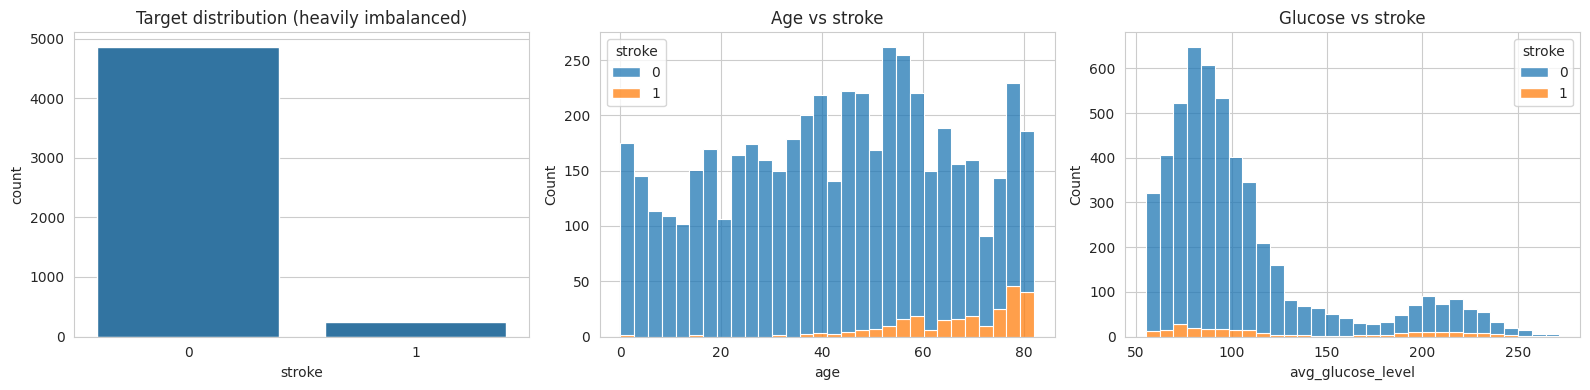

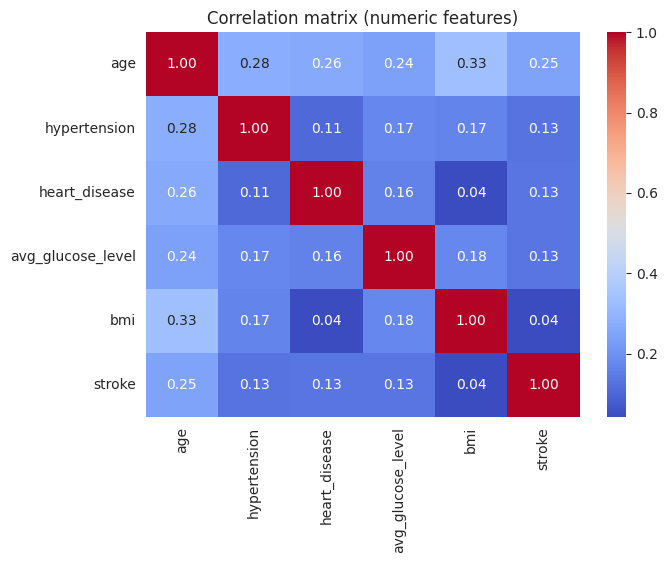

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x='stroke', data=df, ax=ax[0]); ax[0].set_title('Target distribution (heavily imbalanced)')
sns.histplot(data=df, x='age', hue='stroke', bins=30, ax=ax[1], multiple='stack'); ax[1].set_title('Age vs stroke')
sns.histplot(data=df, x='avg_glucose_level', hue='stroke', bins=30, ax=ax[2], multiple='stack'); ax[2].set_title('Glucose vs stroke')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns='id').select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix (numeric features)'); plt.show()

## 4. Data preprocessing
Steps:
1. Drop the `id` column (no predictive meaning) and the single `Other` gender row.
2. Convert `bmi` to numeric (it contains `N/A`) and impute missing values with the **training-set median**.
3. One-hot encode categorical features.
4. **Stratified** 70 / 15 / 15 split into train / validation / test (keeps the ~5% stroke rate in each split).
5. Standardise features (scaler fit on training data only, to avoid data leakage).
6. Compute **class weights** because only ~5% of samples are strokes.

In [ ]:
data = df.drop(columns=['id']).copy()
data = data[data['gender'] != 'Other']
data['bmi'] = pd.to_numeric(data['bmi'], errors='coerce')

X = data.drop(columns='stroke')
y = data['stroke'].values

# stratified split: 70 / 15 / 15
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

# impute BMI with the TRAIN median only
bmi_median = X_train['bmi'].median()
for part in (X_train, X_val, X_test):
    part['bmi'] = part['bmi'].fillna(bmi_median)

# one-hot encode categoricals consistently across splits
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_val   = pd.get_dummies(X_val,   columns=cat_cols, drop_first=True).reindex(columns=X_train.columns, fill_value=0)
X_test  = pd.get_dummies(X_test,  columns=cat_cols, drop_first=True).reindex(columns=X_train.columns, fill_value=0)

# scale
scaler = StandardScaler().fit(X_train.astype('float32'))
X_train_s = scaler.transform(X_train.astype('float32'))
X_val_s   = scaler.transform(X_val.astype('float32'))
X_test_s  = scaler.transform(X_test.astype('float32'))

# class weights
cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}

print('Features:', X_train.shape[1])
print('Train/Val/Test:', X_train_s.shape[0], X_val_s.shape[0], X_test_s.shape[0])
print('Stroke rate  train/val/test: %.3f / %.3f / %.3f' % (y_train.mean(), y_val.mean(), y_test.mean()))
print('Class weights:', class_weight)

Features: 15
Train/Val/Test: 3576 766 767
Stroke rate  train/val/test: 0.049 / 0.048 / 0.050
Class weights: {0: np.float64(0.5255731922398589), 1: np.float64(10.275862068965518)}


## 5. Model architecture
A fully-connected Deep Neural Network (DNN) for binary classification:

`Input → Dense(64, ReLU) → BatchNorm → Dropout(0.3) → Dense(32, ReLU) → BatchNorm → Dropout(0.3) → Dense(16, ReLU) → Dense(1, Sigmoid)`

* **ReLU** hidden activations, **sigmoid** output for stroke probability.
* **BatchNorm + Dropout + L2 regularisation** reduce overfitting on a small dataset.
* **Binary cross-entropy** loss, **Adam** optimiser.

In [ ]:
def build_model(n_features):
    reg = keras.regularizers.l2(1e-4)
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation='relu', kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu', kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu', kernel_regularizer=reg),
        layers.Dense(1, activation='sigmoid')
    ], name='stroke_dnn')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy',
                           keras.metrics.AUC(name='auc'),
                           keras.metrics.Precision(name='precision'),
                           keras.metrics.Recall(name='recall')])
    return model

model = build_model(X_train_s.shape[1])
model.summary()

Model: "stroke_dnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 192 (768.00 B)

## 6. Training
* Class weights compensate for the imbalance.
* **EarlyStopping** (monitors validation AUC) stops training when it stops improving and restores the best weights.
* **ReduceLROnPlateau** lowers the learning rate when validation loss stalls.

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=15, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1),
]
history = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                    epochs=150, batch_size=64, class_weight=class_weight,
                    callbacks=callbacks, verbose=2)
print('Stopped after', len(history.history['loss']), 'epochs')

Epoch 1/150
56/56 - 6s - 102ms/step - accuracy: 0.4740 - auc: 0.6346 - loss: 0.7223 - precision: 0.0630 - recall: 0.7069 - val_accuracy: 0.7728 - val_auc: 0.7518 - val_loss: 0.6068 - val_precision: 0.1130 - val_recall: 0.5405 - learning_rate: 0.0010
Epoch 2/150
56/56 - 0s - 5ms/step - accuracy: 0.6163 - auc: 0.7609 - loss: 0.6015 - precision: 0.0947 - recall: 0.8046 - val_accuracy: 0.8146 - val_auc: 0.7645 - val_loss: 0.4888 - val_precision: 0.1168 - val_recall: 0.4324 - learning_rate: 0.0010
Epoch 3/150
56/56 - 0s - 5ms/step - accuracy: 0.6560 - auc: 0.7782 - loss: 0.5769 - precision: 0.1030 - recall: 0.7874 - val_accuracy: 0.8120 - val_auc: 0.7845 - val_loss: 0.4540 - val_precision: 0.1457 - val_recall: 0.5946 - learning_rate: 0.0010
Epoch 4/150
56/56 - 0s - 6ms/step - accuracy: 0.6770 - auc: 0.7875 - loss: 0.5574 - precision: 0.1054 - recall: 0.7529 - val_accuracy: 0.7898 - val_auc: 0.7977 - val_loss: 0.4414 - val_precision: 0.1477 - val_recall: 0.7027 - learning_rate: 0.0010
Epoch 

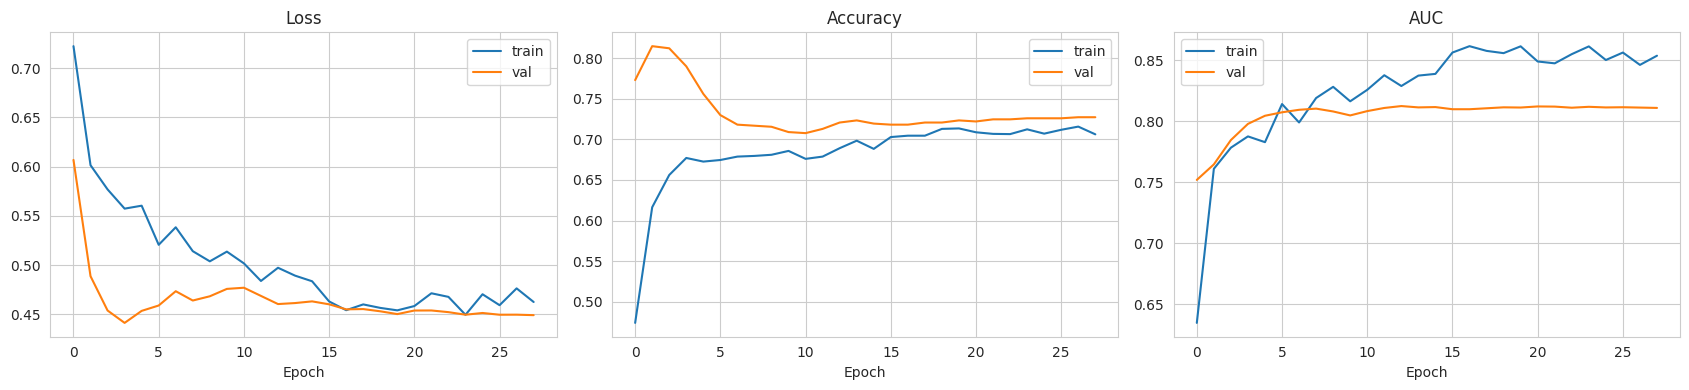

In [ ]:
h = history.history
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h['accuracy'], label='train'); ax[1].plot(h['val_accuracy'], label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
ax[2].plot(h['auc'], label='train'); ax[2].plot(h['val_auc'], label='val'); ax[2].set_title('AUC'); ax[2].legend()
for a in ax: a.set_xlabel('Epoch')
plt.tight_layout(); plt.savefig('dnn_training_curves.png', dpi=150); plt.show()

## 7. Evaluation
Because only ~5% of patients have a stroke, **accuracy is misleading** (predicting "no stroke" for everyone gives ~95%).
We therefore focus on **recall, precision, F1, ROC-AUC and PR-AUC**.
The decision threshold is chosen on the **validation set** (best F1) – not on the test set – and then applied to the untouched test set.

In [ ]:
val_prob  = model.predict(X_val_s, verbose=0).ravel()
test_prob = model.predict(X_test_s, verbose=0).ravel()

# choose the threshold that maximises F1 on the VALIDATION set
thresholds = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_val, val_prob >= t) for t in thresholds]
best_t = thresholds[int(np.argmax(f1s))]
print('Best threshold on validation (max F1): %.2f' % best_t)

def report(y_true, prob, t, name):
    pred = (prob >= t).astype(int)
    print(f'===== {name} (threshold={t:.2f}) =====')
    print('Accuracy : %.4f' % accuracy_score(y_true, pred))
    print('Precision: %.4f' % precision_score(y_true, pred, zero_division=0))
    print('Recall   : %.4f' % recall_score(y_true, pred))
    print('F1-score : %.4f' % f1_score(y_true, pred))
    print('ROC-AUC  : %.4f' % roc_auc_score(y_true, prob))
    print('PR-AUC   : %.4f' % average_precision_score(y_true, prob))
    print(classification_report(y_true, pred, target_names=['No stroke', 'Stroke'], zero_division=0))
    return pred

_ = report(y_test, test_prob, 0.5, 'TEST @ default 0.5')
test_pred = report(y_test, test_prob, best_t, 'TEST @ tuned threshold')

Best threshold on validation (max F1): 0.69
===== TEST @ default 0.5 (threshold=0.50) =====
Accuracy : 0.6949
Precision: 0.1202
Recall   : 0.8158
F1-score : 0.2095
ROC-AUC  : 0.8023
PR-AUC   : 0.1688
              precision    recall  f1-score   support

   No stroke       0.99      0.69      0.81       729
      Stroke       0.12      0.82      0.21        38

    accuracy                           0.69       767
   macro avg       0.55      0.75      0.51       767
weighted avg       0.94      0.69      0.78       767

===== TEST @ tuned threshold (threshold=0.69) =====
Accuracy : 0.8670
Precision: 0.1735
Recall   : 0.4474
F1-score : 0.2500
ROC-AUC  : 0.8023
PR-AUC   : 0.1688
              precision    recall  f1-score   support

   No stroke       0.97      0.89      0.93       729
      Stroke       0.17      0.45      0.25        38

    accuracy                           0.87       767
   macro avg       0.57      0.67      0.59       767
weighted avg       0.93      0.87      0.

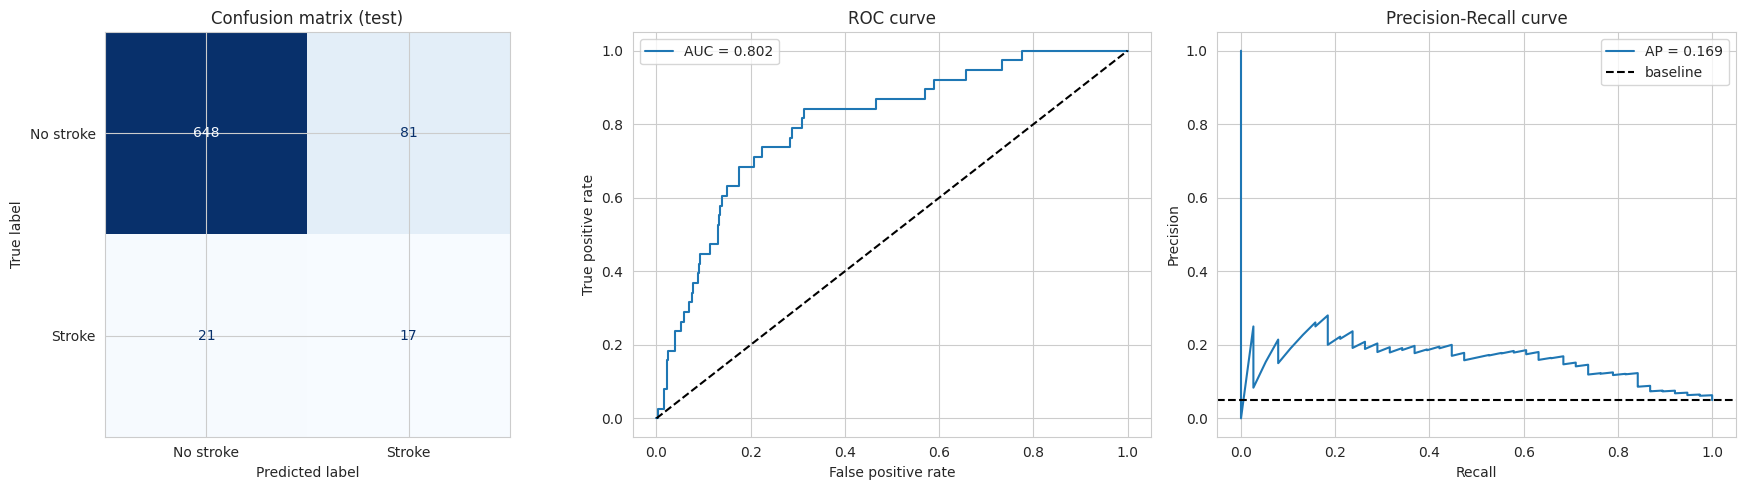

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=['No stroke', 'Stroke']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix (test)')

fpr, tpr, _ = roc_curve(y_test, test_prob)
ax[1].plot(fpr, tpr, label='AUC = %.3f' % roc_auc_score(y_test, test_prob)); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].set_title('ROC curve'); ax[1].legend()

p, r, _ = precision_recall_curve(y_test, test_prob)
ax[2].plot(r, p, label='AP = %.3f' % average_precision_score(y_test, test_prob))
ax[2].axhline(y_test.mean(), color='k', ls='--', label='baseline')
ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].set_title('Precision-Recall curve'); ax[2].legend()
plt.tight_layout(); plt.savefig('dnn_evaluation.png', dpi=150); plt.show()

## 8. Baseline comparison (Logistic Regression)
A simple baseline shows whether the DNN actually adds value.

In [ ]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train_s, y_train)
lr_prob = lr.predict_proba(X_test_s)[:, 1]
print('Logistic Regression  ROC-AUC: %.4f | PR-AUC: %.4f' % (roc_auc_score(y_test, lr_prob), average_precision_score(y_test, lr_prob)))
print('DNN                  ROC-AUC: %.4f | PR-AUC: %.4f' % (roc_auc_score(y_test, test_prob), average_precision_score(y_test, test_prob)))

Logistic Regression  ROC-AUC: 0.8371 | PR-AUC: 0.1924
DNN                  ROC-AUC: 0.8023 | PR-AUC: 0.1688


## 9. Conclusion
* A DNN was trained on 5,109 patient records to predict stroke from 10 demographic / clinical features (15 after one-hot encoding).
* The dataset is severely imbalanced (~5% positive). Class weighting, a validation-tuned threshold and imbalance-aware metrics (recall, F1, ROC-AUC, PR-AUC) were used instead of relying on accuracy.
* The DNN ranks patients by risk reasonably well (ROC-AUC around 0.80) and at the default 0.5 threshold catches most stroke cases (high recall) at the cost of many false alarms (low precision). Raising the threshold trades recall for precision.
* The simple Logistic Regression baseline performed as well as or better than the DNN. With only ~249 positive cases and mostly tabular features, a deeper model has little extra signal to learn from.
* Limitations: very few positive cases (the test set has only ~38), so results vary from run to run; the model is a **screening aid, not a diagnostic tool**.
* Future work: SMOTE/oversampling, cross-validation, gradient-boosting comparison, and SHAP explanations.

## 10. Save the trained DNN as `.joblib` and run inference

The artifact stores the trained network architecture and weights together with the fitted scaler, feature-column order, BMI imputation value, and validation-selected decision threshold. This lets the model accept new patient records in their original raw-column format.

In [ ]:
# Save a complete inference artifact (run after training and evaluation)
DNN_JOBLIB_PATH = 'stroke_dnn_model.joblib'

dnn_artifact = {
    'architecture_json': model.to_json(),
    'weights': model.get_weights(),
    'scaler': scaler,
    'feature_columns': list(X_train.columns),
    'raw_columns': list(X.columns),
    'categorical_columns': ['gender', 'ever_married', 'work_type',
                            'Residence_type', 'smoking_status'],
    'bmi_median': float(bmi_median),
    'threshold': float(best_t),
    'class_names': ['No stroke', 'Stroke'],
    'test_metrics': {
        'accuracy': float(accuracy_score(y_test, test_pred)),
        'precision': float(precision_score(y_test, test_pred, zero_division=0)),
        'recall': float(recall_score(y_test, test_pred, zero_division=0)),
        'f1': float(f1_score(y_test, test_pred, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_test, test_prob)),
        'pr_auc': float(average_precision_score(y_test, test_prob))
    }
}
joblib.dump(dnn_artifact, DNN_JOBLIB_PATH, compress=3)
print(f'Saved {DNN_JOBLIB_PATH} ({os.path.getsize(DNN_JOBLIB_PATH)/1024:.1f} KB)')

def load_dnn_joblib(path=DNN_JOBLIB_PATH):
    artifact = joblib.load(path)
    net = keras.models.model_from_json(artifact['architecture_json'])
    net.set_weights(artifact['weights'])
    return net, artifact

def prepare_patient_rows(patients, artifact):
    if isinstance(patients, dict):
        patients = [patients]
    raw = pd.DataFrame(patients)
    required = artifact['raw_columns']
    missing = [c for c in required if c not in raw.columns]
    if missing:
        raise ValueError(f'Missing required patient fields: {missing}')
    raw = raw[required].copy()
    raw['bmi'] = pd.to_numeric(raw['bmi'], errors='coerce').fillna(artifact['bmi_median'])
    cats = artifact['categorical_columns']
    encoded = pd.get_dummies(raw, columns=cats, drop_first=True)
    encoded = encoded.reindex(columns=artifact['feature_columns'], fill_value=0)
    return artifact['scaler'].transform(encoded.astype('float32'))

def predict_stroke(patients, net, artifact):
    X_new = prepare_patient_rows(patients, artifact)
    probabilities = net.predict(X_new, verbose=0).ravel()
    predictions = (probabilities >= artifact['threshold']).astype(int)
    result = pd.DataFrame({
        'stroke_probability': np.round(probabilities, 4),
        'prediction': np.where(predictions == 1, 'Stroke risk: HIGH', 'Stroke risk: LOW')
    })
    return result

# Reload the saved artifact and run inference on example raw patient records
loaded_dnn, loaded_dnn_artifact = load_dnn_joblib()
example_patients = [
    {'gender':'Male', 'age':67, 'hypertension':0, 'heart_disease':1,
     'ever_married':'Yes', 'work_type':'Private', 'Residence_type':'Urban',
     'avg_glucose_level':228.69, 'bmi':36.6, 'smoking_status':'formerly smoked'},
    {'gender':'Female', 'age':24, 'hypertension':0, 'heart_disease':0,
     'ever_married':'No', 'work_type':'Private', 'Residence_type':'Rural',
     'avg_glucose_level':85.1, 'bmi':22.4, 'smoking_status':'never smoked'}
]
print(predict_stroke(example_patients, loaded_dnn, loaded_dnn_artifact))

# Verify reload consistency on the held-out test set
reloaded_test_prob = loaded_dnn.predict(X_test_s, verbose=0).ravel()
print('Maximum reload probability difference:',
      float(np.max(np.abs(reloaded_test_prob - test_prob))))

try:
    from google.colab import files
    files.download(DNN_JOBLIB_PATH)
except ImportError:
    pass
